# <center>**Chapter 28 - Text Generation with LSTM in PyTorch**<center>

**Mục tiêu:** Xây dựng mô hình character-level LSTM để học quy luật ký tự trong *Alice’s Adventures in Wonderland*, sau đó sinh văn bản từ một prompt ngẫu nhiên.

**Phương pháp — chạy demo:** Tiền xử lý văn bản ASCII, tạo ánh xạ ký tự-số và dùng cửa sổ 40 ký tự để dự đoán ký tự kế tiếp bằng CrossEntropyLoss. Phiên chạy chỉ dùng tối đa 20.000 mẫu, 64 đơn vị ẩn, 1 epoch cho mô hình 1 tầng và 1 epoch cho mô hình 2 tầng (Stacked LSTM), với mục tiêu minh họa luồng thực hiện nhanh.

In [12]:
import os
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

torch.manual_seed(42)
np.random.seed(42)

DATA_DIR = os.path.join("data")
os.makedirs(DATA_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị:", device)

Thiết bị: cpu


## **1. Tải và tiền xử lý corpus**

Loại bỏ phần Gutenberg header/footer nếu vẫn còn trong file, chuyển toàn bộ văn bản sang chữ thường và lập bảng ánh xạ mọi ký tự duy nhất.

In [13]:
filename = os.path.join(DATA_DIR, "wonderland.txt")
with open(filename, "r", encoding="utf-8") as f:
    raw_text = f.read()

start_marker = "*** START OF THIS PROJECT GUTENBERG EBOOK ALICE'S ADVENTURES IN WONDERLAND ***"
end_marker = "THE END"
start_index = raw_text.find(start_marker)
if start_index != -1:
    raw_text = raw_text[start_index + len(start_marker):]
end_index = raw_text.find(end_marker)
if end_index != -1:
    raw_text = raw_text[:end_index]

raw_text = raw_text.lower()
chars = sorted(set(raw_text))
char_to_int = {char: i for i, char in enumerate(chars)}
int_to_char = {i: char for char, i in char_to_int.items()}
n_chars = len(raw_text)
n_vocab = len(chars)

print("Tổng ký tự:", n_chars)
print("Vốn từ ký tự:", n_vocab)
print("Ký tự:", repr("".join(chars)))

Tổng ký tự: 144434
Vốn từ ký tự: 45
Ký tự: '\n !"\'()*,-.03:;?[]_abcdefghijklmnopqrstuvwxyz'


## **2. Tạo dataset cửa sổ trượt**

Chế độ demo dùng chuỗi ngắn hơn và một tập mẫu giới hạn để chạy nhanh. Mỗi mẫu gồm 40 ký tự liên tiếp và nhãn là ký tự thứ 41; dữ liệu đầu vào được chuẩn hóa chia cho `n_vocab`.

In [14]:
seq_length = 40
# Chế độ demo: chỉ lấy tối đa 20.000 mẫu để chạy nhanh.
n_patterns_limit = 20000
dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])
    if len(dataX) >= n_patterns_limit:
        break

n_patterns = len(dataX)
X = torch.tensor(dataX, dtype=torch.float32).reshape(n_patterns, seq_length, 1)
X = X / float(n_vocab)
y = torch.tensor(dataY, dtype=torch.long)

print("Số pattern:", n_patterns)
print("Kích thước X:", tuple(X.shape), "| y:", tuple(y.shape))

Số pattern: 20000
Kích thước X: (20000, 40, 1) | y: (20000,)


## **3. Mô hình LSTM 1 tầng**

Chế độ demo dùng 64 đơn vị ẩn, dropout 0.2 và lớp tuyến tính đầu ra tương ứng các ký tự trong từ vựng. Chỉ hidden state của timestep cuối được đưa tới output.

In [15]:
class CharModel(nn.Module):
    def __init__(self, num_layers=1, hidden_size=64, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1,
                            hidden_size=hidden_size,
                            num_layers=num_layers,
                            batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_size, n_vocab)

    def forward(self, x):
        hidden_states, _ = self.lstm(x)
        last_state = hidden_states[:, -1, :]
        return self.linear(self.dropout(last_state))

model = CharModel(num_layers=1).to(device)
print(model)

CharModel(
  (lstm): LSTM(1, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (linear): Linear(in_features=64, out_features=45, bias=True)
)


## **4. Huấn luyện mô hình 1 tầng**

Chế độ demo chỉ huấn luyện 1 epoch và không đánh giá lại toàn bộ dữ liệu sau epoch để thời gian chạy ngắn. Đây là luồng chạy minh họa, không nhằm đạt chất lượng sinh văn bản cao.

In [16]:
batch_size = 512
n_epochs = 1
loader = data.DataLoader(data.TensorDataset(X, y), shuffle=True, batch_size=batch_size)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(reduction="sum")
best_loss = float("inf")
best_state = None
history_single = []

for epoch in range(n_epochs):
    model.train()
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Đánh giá nhanh trên một batch thay vì toàn bộ tập dữ liệu.
    model.eval()
    with torch.no_grad():
        sample_X, sample_y = next(iter(loader))
        sample_pred = model(sample_X.to(device))
        total_loss = loss_fn(sample_pred, sample_y.to(device)).item()
    history_single.append(total_loss)
    best_loss = total_loss
    best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:2d}: Demo batch cross-entropy = {total_loss:.4f}")

# Lưu trọng số tốt nhất và bảng ánh xạ để tái sử dụng sau này.
if best_state is not None:
    single_checkpoint = os.path.join(DATA_DIR, "single-char.pth")
    torch.save([best_state, char_to_int], single_checkpoint)
    print("Đã lưu checkpoint:", single_checkpoint)

Epoch  0: Demo batch cross-entropy = 1527.6211
Đã lưu checkpoint: data\single-char.pth


## **5. Sinh văn bản bằng mô hình 1 tầng**

Chọn ngẫu nhiên một đoạn 40 ký tự làm prompt. Mô hình dự đoán ký tự có logits cao nhất, thêm ký tự đó vào cuối chuỗi, bỏ ký tự đầu và lặp lại.

**Kết quả demo:** Sau 1 epoch, văn bản sinh ra chủ yếu lặp lại khoảng trắng hoặc gần prompt. Đây là kết quả mong đợi ở phiên huấn luyện cực ngắn, không đại diện cho chất lượng mô hình sau 40 epoch.

In [17]:
def generate_text(model, prompt, char_to_int, int_to_char, steps=500, temperature=1.0):
    # Sinh chuỗi ký tự theo greedy decoding.
    model.eval()
    pattern = [char_to_int[c] for c in prompt]
    generated = []
    with torch.no_grad():
        for _ in range(steps):
            x = np.asarray(pattern, dtype=np.float32).reshape(1, len(pattern), 1)
            x = torch.tensor(x / float(n_vocab), dtype=torch.float32, device=device)
            logits = model(x)
            index = int(logits.argmax(dim=1).item())
            generated.append(int_to_char[index])
            pattern.append(index)
            pattern = pattern[-seq_length:]
    return prompt + "".join(generated)

start = np.random.randint(0, len(raw_text) - seq_length)
prompt = raw_text[start:start + seq_length]

print("Prompt:", repr(prompt))
print(generate_text(model, prompt, char_to_int, int_to_char, steps=100))

Prompt: "he\ndistance.\n\n'come on!' cried the gryph"
he
distance.

'come on!' cried the gryph                                                                                                    


## **6. Mô hình Stacked LSTM 2 tầng**

Tầng LSTM thứ hai tiếp nhận chuỗi hidden state của tầng thứ nhất thay vì chỉ nhận đầu vào thô. PyTorch hỗ trợ bằng `num_layers=2` và dropout liên tầng.

In [18]:
stacked_model = CharModel(num_layers=2, hidden_size=64, dropout=0.2).to(device)
print(stacked_model)

CharModel(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (linear): Linear(in_features=64, out_features=45, bias=True)
)


In [19]:
n_epochs_stacked = 1
loader = data.DataLoader(data.TensorDataset(X, y), shuffle=True, batch_size=batch_size)
optimizer = optim.Adam(stacked_model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(reduction="sum")
best_loss = float("inf")
best_state = None
history_stacked = []

for epoch in range(n_epochs_stacked):
    stacked_model.train()
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        y_pred = stacked_model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    stacked_model.eval()
    with torch.no_grad():
        sample_X, sample_y = next(iter(loader))
        sample_pred = stacked_model(sample_X.to(device))
        total_loss = loss_fn(sample_pred, sample_y.to(device)).item()
    history_stacked.append(total_loss)
    best_loss = total_loss
    best_state = copy.deepcopy(stacked_model.state_dict())
    print(f"Epoch {epoch:2d}: Demo batch cross-entropy = {total_loss:.4f}")

stacked_checkpoint = os.path.join(DATA_DIR, "stacked-char.pth")
torch.save([best_state, char_to_int], stacked_checkpoint)
print("Đã lưu checkpoint:", stacked_checkpoint)

Epoch  0: Demo batch cross-entropy = 1570.4702
Đã lưu checkpoint: data\stacked-char.pth


## **7. Demo mô hình Stacked LSTM và sinh văn bản**

Dùng checkpoint mô hình stacked đã huấn luyện 1 epoch để sinh 100 ký tự. Đây chỉ là demo nhanh; văn bản sinh ra vẫn lặp khoảng trắng và chưa học đủ để tạo câu tự nhiên.

In [20]:
stacked_model.load_state_dict(best_state)
start = np.random.randint(0, len(raw_text) - seq_length)
prompt_stacked = raw_text[start:start + seq_length]

print("Prompt stacked:", repr(prompt_stacked))
print(generate_text(stacked_model, prompt_stacked, char_to_int, int_to_char, steps=100))

Prompt stacked: "t dormouse,' the queen shrieked out. 'be"
t dormouse,' the queen shrieked out. 'be                                                                                                    


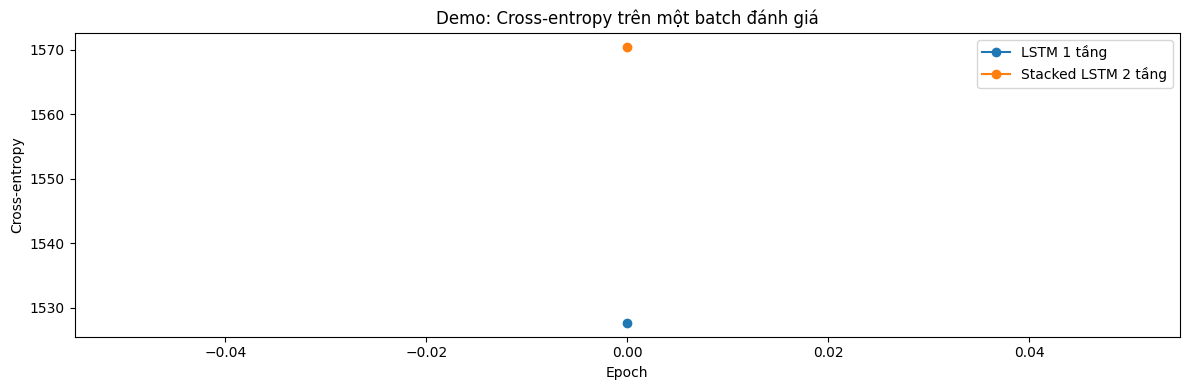

In [21]:
# Cross-entropy trên tập huấn luyện
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(history_single, marker="o", label="LSTM 1 tầng")
plt.plot(history_stacked, marker="o", label="Stacked LSTM 2 tầng")
plt.title("Demo: Cross-entropy trên một batch đánh giá")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
print("Kiểm tra GPU:", torch.cuda.is_available())

Kiểm tra GPU: False


## **Kết luận**

- **Đây là lần chạy demo trên CPU**, không phải huấn luyện full: 20.000 mẫu, chuỗi 40 ký tự, 64 hidden units và 1 epoch cho mỗi mô hình.
- Mô hình 1 tầng đạt demo batch Cross-entropy 1527.6211; mô hình stacked 2 tầng đạt 1570.4702. Hai giá trị chỉ mang tính minh họa trên batch được chọn ngẫu nhiên, chưa phải đánh giá toàn bộ dữ liệu.
- Văn bản sinh ra còn lặp khoảng trắng và gần prompt. Điều này phù hợp với huấn luyện 1 epoch; không thể kết luận stacked LSTM tốt hơn hoặc đã hội tụ.
- Để cải thiện rõ ràng, cần tăng epoch (ví dụ 40 epoch theo PDF), dùng nhiều mẫu hơn hoặc toàn bộ 144.000+ mẫu, tăng hidden size và đánh giá trên toàn bộ tập dữ liệu.
- Khi chạy GPU, model, input và target phải cùng device.

# <center>**HẾT**<center>